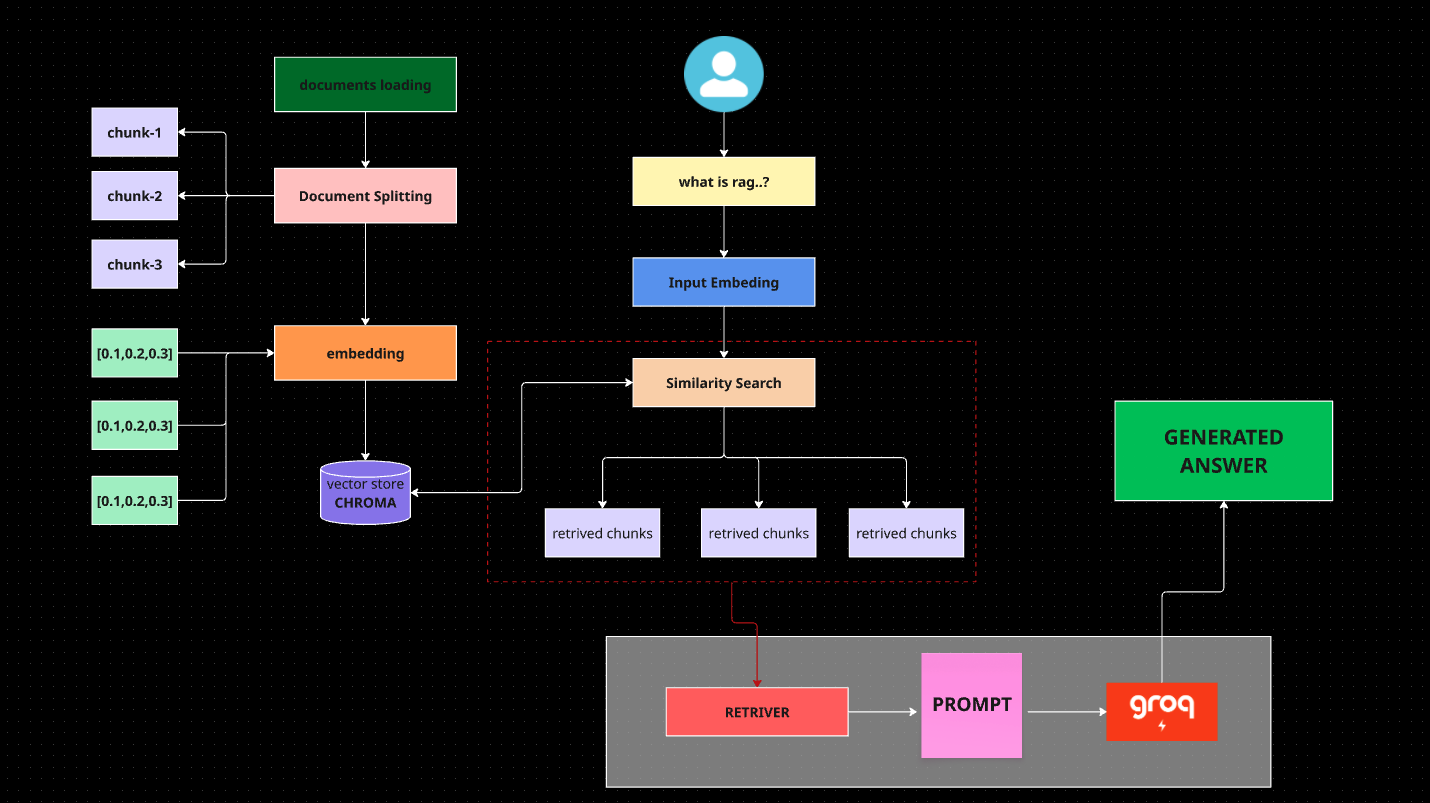

# Production DB series

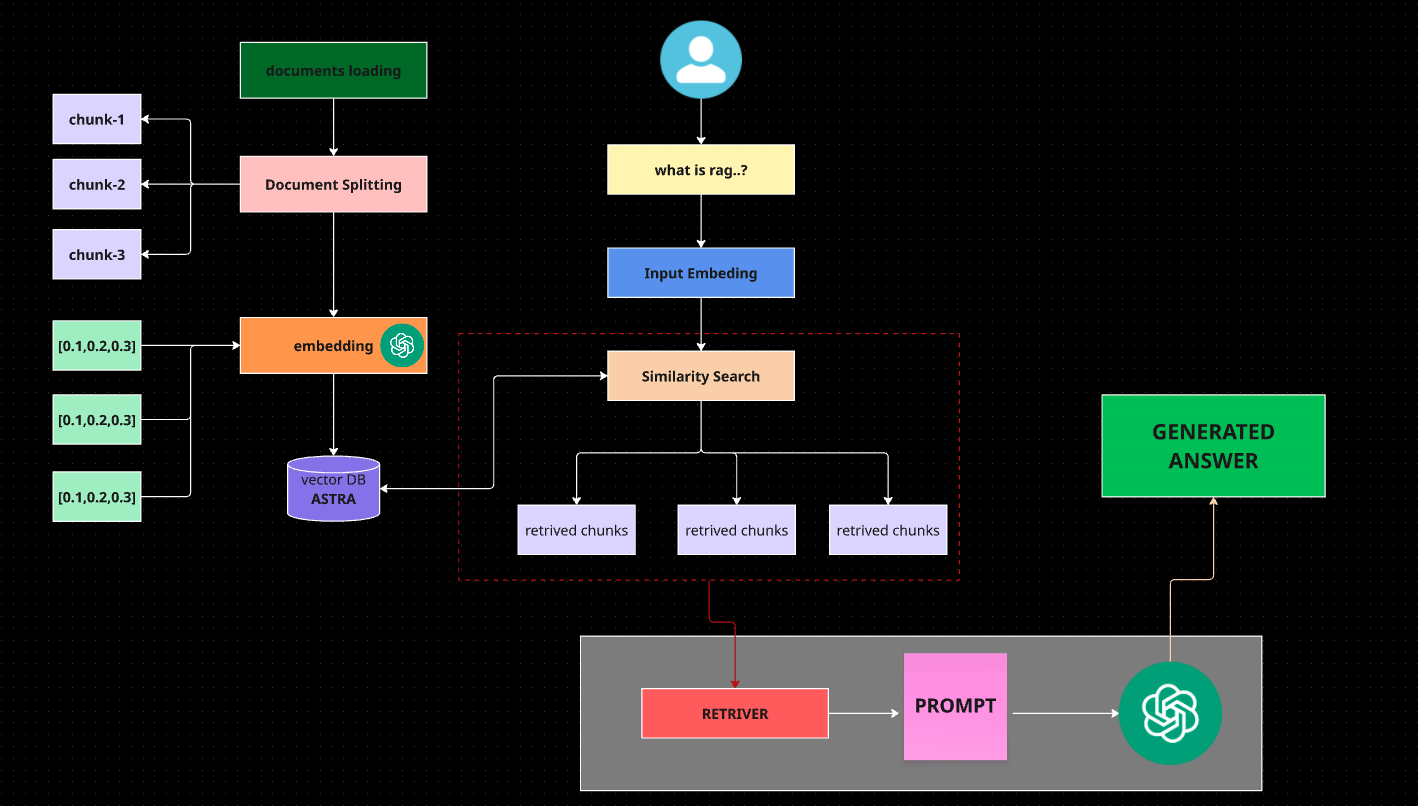

In [3]:
import os
from dotenv import load_dotenv
load_dotenv(override=True)

# PDF loading
from langchain_community.document_loaders import PyMuPDFLoader,DirectoryLoader

# Text Splitting 
from langchain_text_splitters import RecursiveCharacterTextSplitter

# Embeding
from langchain_openai import OpenAIEmbeddings



/var/folders/m8/jv_qd8md6_n84v8zcshwvjm40000gn/T/ipykernel_89504/2330421024.py:6: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyMuPDFLoader,DirectoryLoader


In [4]:
# Loading the PDFS

dir_loader = DirectoryLoader(
    "pdfdoc",
    glob = "*.pdf",
    loader_cls=PyMuPDFLoader
)

In [5]:
documents = dir_loader.load()
print(f"Total documents loaded is {len(documents)}")

Total documents loaded is 1478


In [6]:
# Document Splitting
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size = 2000,
    chunk_overlap = 500,
)

chunks = text_splitter.split_documents(documents)
print(f"created chunks is {len(chunks)} from documents loaded is {len(documents)}")


created chunks is 2433 from documents loaded is 1478


In [7]:
import os
from dotenv import load_dotenv
load_dotenv(override=True)

os.environ["OPENAI_API_KEY"] = os.getenv("OPENAI_API_KEY")

In [8]:
## https://developers.openai.com/api/docs/guides/embeddings

embedding = OpenAIEmbeddings(
    model = "text-embedding-3-small"
)

In [9]:
sample_text = "Hello Everyone how are yoy...."
vector = embedding.embed_query(sample_text)


In [10]:
len(vector)

1536

In [19]:
vector[:10]

[0.08502197265625,
 -0.040863037109375,
 -0.06689453125,
 0.042022705078125,
 0.046173095703125,
 0.01291656494140625,
 0.005687713623046875,
 -0.0047760009765625,
 -0.0180816650390625,
 -0.05322265625]

# ASTRA DB

https://docs.datastax.com/en/astra-db-serverless/index.html



In [11]:
import os
from dotenv import load_dotenv
load_dotenv(override=True)


os.environ["ASTRA_DB_API_ENDPOINT"] = os.getenv("ASTRA_DB_API_ENDPOINT")
os.environ["ASTRA_DB_APPLICATION_TOKEN"] = os.getenv("ASTRA_DB_APPLICATION_TOKEN")

ASTRA_DB_API_ENDPOINT = os.getenv("ASTRA_DB_API_ENDPOINT")
ASTRA_DB_APPLICATION_TOKEN = os.getenv("ASTRA_DB_APPLICATION_TOKEN")

In [12]:
from langchain_astradb import AstraDBVectorStore
from astrapy.api_options import APIOptions,TimeoutOptions

api_options = APIOptions(
    timeout_options = TimeoutOptions(
        request_timeout_ms=180000,
        general_method_timeout_ms=180000
    )
)


vector_db = AstraDBVectorStore(
    embedding=embedding,
    api_endpoint=ASTRA_DB_API_ENDPOINT,
    token=ASTRA_DB_APPLICATION_TOKEN,
    collection_name="astradb_vetcor_collections",
    namespace=None,
    api_options = api_options
)

In [ ]:
vetcors_result = vector_db.add_documents(chunks)

In [13]:
query = "what is python.?"

similar_docs = vector_db.similarity_search(
    query,
    k=3
)
similar_docs

[Document(id='19a0e97a9f7c4093a39ba8d772adfc97', metadata={'producer': 'Antenna House PDF Output Library 2.6.0 (Linux)', 'creator': 'XSL Formatter V4.3 R1 (4,3,2008,0424) for Linux', 'creationdate': '2009-09-14T12:13:26-05:00', 'source': 'pdfdoc/Learning_Python.pdf', 'file_path': 'pdfdoc/Learning_Python.pdf', 'total_pages': 1213, 'format': 'PDF 1.6', 'title': 'Learning Python', 'author': 'Mark Lutz', 'subject': '', 'keywords': '', 'moddate': '2009-09-24T12:55:28-07:00', 'trapped': '', 'modDate': "D:20090924125528-07'00'", 'creationDate': "D:20090914121326-05'00'", 'page': 1}, page_content='Learning Python'),
 Document(id='53e13986c997446791b16f32cc1700d3', metadata={'producer': 'Antenna House PDF Output Library 2.6.0 (Linux)', 'creator': 'XSL Formatter V4.3 R1 (4,3,2008,0424) for Linux', 'creationdate': '2009-09-14T12:13:26-05:00', 'source': 'pdfdoc/Learning_Python.pdf', 'file_path': 'pdfdoc/Learning_Python.pdf', 'total_pages': 1213, 'format': 'PDF 1.6', 'title': 'Learning Python', 'au

In [14]:
# stage-6 creating retriver

retriver = vector_db.as_retriever(
    search_kwargs = {
        "k" :3 
    }
)

In [27]:
docs = retriver.invoke("What is python.?")

for doc in docs:
    print(doc.page_content)

Learning Python
Library utilities
For more specific tasks, Python also comes with a large collection of precoded
library tools that support everything from regular expression matching to net-
working. Once you learn the language itself, Python’s library tools are where much
of the application-level action occurs.
Third-party utilities
Because Python is open source, developers are encouraged to contribute precoded
tools that support tasks beyond those supported by its built-ins; on the Web, you’ll
find free support for COM, imaging, CORBA ORBs, XML, database access, and
much more.
Despite the array of tools in Python, it retains a remarkably simple syntax and design.
The result is a powerful programming tool with all the usability of a scripting language.
It’s Mixable
Python programs can easily be “glued” to components written in other languages in a
variety of ways. For example, Python’s C API lets C programs call and be called by
Python programs flexibly. That means you can add functi

In [28]:
# stage-7 
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(
    model = "gpt-4o"
)

In [29]:
llm.invoke("Hello")

AIMessage(content='Hello! How can I assist you today?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 9, 'prompt_tokens': 8, 'total_tokens': 17, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-2024-08-06', 'system_fingerprint': 'fp_f89046aead', 'id': 'chatcmpl-EdI9Y0PG896Sodqto03rIhJBxrEK8', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1791c-9923-7063-8860-8915c7d9c7eb-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 8, 'output_tokens': 9, 'total_tokens': 17, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}})

In [30]:
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.runnables import RunnablePassthrough
from langchain_core.output_parsers import StrOutputParser

cutom_prompt = ChatPromptTemplate.from_template(
    """ 
    you are helpfull assistant.

    answer the question using only provided context

    if the answer cannot be found in context or the retriver result then say
    "I dont know your question please ask only in the knowlede base" 

    Context:
    {context}

    Question:
    {question}

    Answer:

    """
)

In [31]:

def formated_docs(docs):
    context = ""

    for doc in docs:
        context +=doc.page_content + "\n\n"

    return context
    

ragchain = (
    
    {
        "context":retriver | formated_docs,
        "question":RunnablePassthrough()
    }
    | cutom_prompt
    | llm
    | StrOutputParser()

)

In [33]:
query = "what is python.?"
answer = ragchain.invoke(query)
print(answer)

Python is a simple language used for quickly coding tasks, allowing much faster program development than compiled languages like C++. It fosters an exploratory, incremental mode of programming due to its rapid development cycle. Python makes tasks simple with its ease of use and flexibility, despite having a simple feature set.


In [34]:
query = "what is Sequence Assignments"
answer = ragchain.invoke(query)
print(answer)

I don't know your question; please ask only in the knowledge base.
